### 1. Data loading and overview


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")

In [2]:
PATH = "../../Data/raw/airport_reviews.csv"
df = pd.read_csv(PATH, encoding="utf-8-sig")
df.shape

(49505, 19)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49505 entries, 0 to 49504
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   review_id              49505 non-null  int64  
 1   airport_id             49505 non-null  int64  
 2   verify                 49505 non-null  int64  
 3   date_submitted         49505 non-null  object 
 4   date_visit             32183 non-null  object 
 5   customer_name          49505 non-null  object 
 6   nationality            46398 non-null  object 
 7   experience_at_airport  32256 non-null  object 
 8   type_of_traveller      32234 non-null  object 
 9   queuing_times          44287 non-null  float64
 10  terminal_cleanliness   44199 non-null  float64
 11  terminal_seating       28092 non-null  float64
 12  terminal_signs         31586 non-null  float64
 13  food_beverages         25303 non-null  float64
 14  airport_shopping       35139 non-null  float64
 15  ai

In [4]:
df.sample(10, random_state=42)

,review_id,airport_id,verify,date_submitted,date_visit,customer_name,nationality,experience_at_airport,type_of_traveller,queuing_times,terminal_cleanliness,terminal_seating,terminal_signs,food_beverages,airport_shopping,airport_staff,wifi_connectivity,recommended,review
3150,3151,40,0,2017-08-23,2017-08-01,Melissa Taylor 16,United Kingdom,Departure Only,Family Leisure,4.0,5.0,4.0,5.0,NaN,4.0,3.0,NaN,1,One of the best airports I have flown from. Airport access is extreamly easy...
12457,12458,272,1,2026-01-29,2026-01-01,James Hall 19,Germany,Arrival and Departure,Business,5.0,5.0,5.0,5.0,3.0,4.0,5.0,5.0,1,Small but clean airport. Time from door to gate was less than 10 minutes. Ai...
19647,19648,394,1,2019-07-31,2019-07-01,Jennifer Young 5,United States,Arrival and Departure,Family Leisure,3.0,3.0,NaN,3.0,NaN,NaN,1.0,NaN,0,The worst airport for customer service. We were ignored by staff too busy go...
12946,12947,256,0,2023-06-26,2023-06-01,Brian Wilson 31,United States,Arrival and Departure,Family Leisure,1.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,0,Denver Airport is a joke. So is the rude staff and lack of service. I hate t...
30097,30098,529,0,2013-07-02,NaN,Carlos Martinez 22,United Kingdom,NaN,NaN,2.0,3.0,NaN,NaN,NaN,3.0,NaN,NaN,0,Check-in at T5 was easy. Security was another matter. Almost all of the lane...
20255,20256,404,0,2016-05-05,2016-04-01,Cynthia Moore 26,Philippines,Arrival Only,Business,1.0,5.0,5.0,5.0,5.0,4.0,4.0,2.0,0,I have spent the past four years using Incheon Airport and the immigration q...
20506,20507,414,0,2023-07-21,2023-07-01,Kenneth Walker 16,Kuwait,Arrival and Departure,Family Leisure,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0,Problems with this airport started a few years ago when they allowed 10x mor...
23986,23987,505,0,2016-03-20,2016-03-01,Nancy Hall 28,United States,Departure Only,Family Leisure,1.0,1.0,NaN,1.0,NaN,NaN,1.0,NaN,0,Just went through security at McCarran airport. The TSA members there were v...
36871,36872,651,0,2006-12-20,NaN,Steven Green 25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,A nice and easy to handle airport in the south of Germany - not many interna...
2213,2214,55,0,2026-05-23,2026-05-01,Brian Anderson 14,Mexico,Departure Only,Family Leisure,2.0,4.0,1.0,3.0,3.0,3.0,1.0,5.0,0,The security check is horrible. People cut the line and no one cares. The pr...


In [5]:
rating_cols = ["queuing_times", "terminal_cleanliness", "terminal_seating", "terminal_signs", "food_beverages", "airport_shopping", "airport_staff", "wifi_connectivity"]
df[rating_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
queuing_times,44287.0,2.38,1.51,1.0,1.0,2.0,4.0,5.0
terminal_cleanliness,44199.0,3.04,1.39,1.0,2.0,3.0,4.0,5.0
terminal_seating,28092.0,2.38,1.39,1.0,1.0,2.0,3.0,5.0
terminal_signs,31586.0,2.73,1.43,1.0,1.0,3.0,4.0,5.0
food_beverages,25303.0,2.37,1.34,1.0,1.0,2.0,3.0,5.0
airport_shopping,35139.0,2.59,1.36,1.0,1.0,3.0,4.0,5.0
airport_staff,29496.0,2.18,1.44,1.0,1.0,1.0,3.0,5.0
wifi_connectivity,21776.0,2.55,1.46,1.0,1.0,2.0,4.0,5.0


In [6]:
category_cols = ["experience_at_airport", "type_of_traveller", "nationality"]
df[category_cols].describe().T

,count,unique,top,freq
experience_at_airport,32256,4,Departure Only,12337
type_of_traveller,32234,4,Couple Leisure,9637
nationality,46398,1845,United Kingdom,15792


In [7]:
df.nunique().sort_values(ascending=False)

review_id                49505
review                   48818
customer_name            33296
date_submitted            6171
nationality               1845
airport_id                1004
date_visit                 144
airport_shopping             5
terminal_cleanliness         5
terminal_seating             5
queuing_times                5
wifi_connectivity            5
airport_staff                5
food_beverages               5
terminal_signs               5
experience_at_airport        4
type_of_traveller            4
verify                       2
recommended                  2
dtype: int64

#### Overview notes

- The table has 49,505 rows and 19 columns, and each row is one review of an airport.
- Columns with the wrong data type: `date_submitted`, `date_visit` (to be fixed in the cleaning section).
- The 8 rating columns use a scale from 1.0 to 5.0, and the number of non-null values differs a lot between columns.
- `review` has 48,818 unique values for 49,505 rows, so some review texts appear more than once (to be checked in the data quality section).


### 2. Data quality and cleaning


In [8]:
#Missing values
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
missing.to_frame("missing_pct")

,missing_pct
wifi_connectivity,56.0
food_beverages,48.9
terminal_seating,43.3
airport_staff,40.4
terminal_signs,36.2
date_visit,35.0
type_of_traveller,34.9
experience_at_airport,34.8
airport_shopping,29.0
terminal_cleanliness,10.7


In [9]:
#Duplicates
cols_no_id = df.columns.drop("review_id")
dup_mask = df.duplicated(subset=cols_no_id, keep=False)
print(f"Rows involved in duplicates: {dup_mask.sum():,}")
df[dup_mask].sort_values(list(cols_no_id[:3])).head(10)

Rows involved in duplicates: 186


,review_id,airport_id,verify,date_submitted,date_visit,customer_name,nationality,experience_at_airport,type_of_traveller,queuing_times,terminal_cleanliness,terminal_seating,terminal_signs,food_beverages,airport_shopping,airport_staff,wifi_connectivity,recommended,review
3754,3755,72,0,2010-07-24,NaN,Carol Garcia,India,NaN,NaN,3.0,3.0,NaN,NaN,NaN,3.0,NaN,NaN,0,Now that it's more than a year since the new airport opened the operations h...
3755,3756,72,0,2010-07-24,NaN,Carol Garcia,India,NaN,NaN,3.0,3.0,NaN,NaN,NaN,3.0,NaN,NaN,0,Now that it's more than a year since the new airport opened the operations h...
7038,7039,134,0,2008-10-09,NaN,Anthony Anderson 28,I think,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,As mentioned an adequate airport. I would describe it as one of the smaller ...
7039,7040,134,0,2008-10-09,NaN,Anthony Anderson 28,I think,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,As mentioned an adequate airport. I would describe it as one of the smaller ...
8993,8994,176,0,2008-10-17,NaN,Sofia Roberts 22,upstairs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,Don't expect too much of this little airport but it is friendly and the depa...
8994,8995,176,0,2008-10-17,NaN,Sofia Roberts 22,upstairs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,Don't expect too much of this little airport but it is friendly and the depa...
9460,9461,193,0,2005-09-12,NaN,Emily Baker 6,DC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,As a resident of Chattanooga I have used this airport on several occasions. ...
9461,9462,193,0,2005-09-12,NaN,Emily Baker 6,DC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,As a resident of Chattanooga I have used this airport on several occasions. ...
10664,10665,217,0,2008-05-20,NaN,Yuki Ramirez 19,temporary?,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,Overall spacious and clean airport. Cheapest long-term parking P3 was full. ...
10665,10666,217,0,2008-05-20,NaN,Yuki Ramirez 19,temporary?,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,Overall spacious and clean airport. Cheapest long-term parking P3 was full. ...


In [10]:
#Check invalid value and dates
df["date_submitted"] = pd.to_datetime(df["date_submitted"], errors="coerce")
df["date_visit"] = pd.to_datetime(df["date_visit"], errors="coerce")

display(df[["date_submitted", "date_visit"]].agg(["min", "max"]))
print("NaT date_submitted:", df["date_submitted"].isna().sum())
print("NaT date_visit", df["date_visit"].isna().sum())

,date_submitted,date_visit
min,2002-07-30,2014-07-01
max,2026-06-20,2026-06-01


NaT date_submitted: 0
NaT date_visit 17322


In [11]:
#Check rows have date_visit > date_submitted
bad = df[df["date_visit"] > df["date_submitted"]].copy()
bad["gap_day"] = (bad["date_visit"] - bad["date_submitted"]).dt.days

display(bad["gap_day"].describe())
display(bad[["airport_id", "date_submitted", "date_visit", "gap_day", "recommended", "verify"]].sort_values("gap_day").head(10))

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: gap_day, dtype: float64

,airport_id,date_submitted,date_visit,gap_day,recommended,verify


In [12]:
#Check review
df["review_len"] = df["review"].str.len()

display(df["review_len"].describe().round(0))
print("Reviews < 20 chars:", (df["review_len"] < 20).sum())
print("Duplicated review text:", df["review"].duplicated().sum())
display(df.groupby("recommended")["review_len"].agg(["count", "mean", "median", "min", "max"]).round(0))

count    49504.0
mean       679.0
std        478.0
min         15.0
25%        353.0
50%        550.0
75%        852.0
max       5122.0
Name: review_len, dtype: float64

Reviews < 20 chars: 3
Duplicated review text: 686


,count,mean,median,min,max
recommended,,,,,
0,37823,700.0,568.0,15.0,5122.0
1,11681,610.0,496.0,52.0,3500.0


In [13]:
#Check nationality
nat = df["nationality"].value_counts()
display(nat.head(15))

print("Distinct nationality value appearing fewer than 5 times", (nat < 5).sum())
rare = nat[nat < 5]
print("Rows covered by those rare values:", rare.sum(), f"({rare.sum() / nat.sum():.2%})")

display(df.loc[df["nationality"].str.len() > 30, "nationality"].head(10))

nationality
United Kingdom    15792
United States      8863
Australia          3075
Canada             1945
Germany            1107
Netherlands         857
Ireland             852
India               782
France              688
Singapore           670
New Zealand         586
Switzerland         523
Malaysia            438
Hong Kong           411
Italy               401
Name: count, dtype: int64

Distinct nationality value appearing fewer than 5 times 1730
Rows covered by those rare values: 1861 (4.01%)


492                                 Democratic Republic of the Congo
867                          with free Internet for paying customers
1011                      company that built Istanbul Intl. Terminal
1093                              arrivals although very slow is ok.
1130                               why are they so fussy about this?
1230    this was last month before AA cancelled their service to ASU
1271                         most sporting superb Gallic moustaches!
1573                                although I wasn't fllying on one
1634    especially when AA used to fly their DC10's into the airport
1677                          especially for the Dubai - Baku flight
Name: nationality, dtype: object

In [14]:
display(df.loc[df["nationality"].str.len() > 30, ["nationality", "review"]].sample(10, random_state=42))

,nationality,review
41908,from Costa Rica Nicaragua Guatemala Cuba etc,"Yes there is a $26 USD departure tax that must be paid before you ""check in""..."
20986,which sees less tourist traffic,I feel that this airport's biggest drawback is having to take a shuttle to a...
35651,often dirty/out of toilet roll/out of order,I use Newcastle frequently to travel around on business. It's really come on...
19069,although I was travelling to the UK,Like Jussi Turunen I found the Security check points staffed by unfriendly u...
18434,found small buckets everywhere on the floor,Airport has a modern design look. Faculty is average compared to the South T...
35285,the rest of a half full 767 were going on to Turks and Caicos,Arrival in NAS off a BA 767. Only about 50 PAX got off (the rest of a half f...
47510,but that is true in every airport,International arrival from Amsterdam: smooth handling from customs to luggag...
20984,it's the only decent coffee outlet,An average airport. Queues for immigration are the usual TSA story - too man...
5212,something not to be taken for granted in other airports,This regional size airport is a gem. Not only does it have great design but ...
18488,this can change during international fairs,Hannover airport is a middle-sized airport in Northern Germany. It offers th...


#### Cleaning decisions

| Issue                                                            | Rows affected           | Decision                                                                                          | Reason                                                                                    |
| ---------------------------------------------------------------- | ----------------------- | ------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------- |
| Date columns stored as text                                      | all                     | Convert to datetime                                                                               | Needed for time analysis                                                                  |
| Duplicate rows (all columns equal except `review_id`)            | 93                      | Drop, keep first                                                                                  | Same review submitted twice                                                               |
| Reviews with no text (1 blank, 3 with only a verification label) | 4                       | Drop                                                                                              | No text to classify                                                                       |
| `date_visit` later than `date_submitted`                         | 0                       | No action                                                                                         | No inconsistent rows found                                                                |
| `date_visit` missing                                             | 17,230 (after cleaning) | Keep as NaT                                                                                       | Only filled for reviews submitted from June 2015, earlier reviews have it missing         |
| Same review text under different airports                        | 686                     | Keep, no action                                                                                   | Cause unknown, decide in the airport comparison section                                   |
| Rare, noisy or missing `nationality`                             | 5,114 (after cleaning)  | Group missing values and values under 10 reviews into "Other" in new column `nationality_grouped` | Many values are text copied from the review, and these rows do not identify a country     |
| `recommended` near 0 in 2002-2010                                | 6,448 (after cleaning)  | Keep, no action                                                                                   | Treated as reliable                                                                       |
| Missing ratings, `type_of_traveller`, `experience_at_airport`    | not imputed             | Keep as NaN                                                                                       | Missing is informative, no reliable way to fill                                           |
| Columns left out of the saved main table                         | 2 columns               | Drop when saving (section 8), raw file is unchanged                                               | `nationality` and `date_visit` are replaced by `nationality_grouped` and `date_submitted` |
| Review text                                                      | all                     | Save in a separate file with `review_id`                                                          | Keeps the main table small, and only the text work needs it                               |

After cleaning: 49,505 → 49,408 rows.


In [15]:
#Clean data
#Countries with at least 10 reviews are kept, the rest (and missing values) become "Other"
keep = nat[nat >= 10].index

df_clean = df.copy()
step = []

# 1.Duplicate rows
n = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=cols_no_id, keep="first")
step.append(("Duplicate rows", n - len(df_clean)))

# 2.Reviews with no text (blank, or only a verification label)
n = len(df_clean)
no_text = df_clean["review"].isna() | df_clean["review"].str.strip().isin(["Not Verified", "✅ Trip Verified"])
df_clean = df_clean[~no_text]
step.append(("No review text", n - len(df_clean)))

# 3.Group nationality (new column, original kept)
df_clean["nationality_grouped"] = df_clean["nationality"].where(df_clean["nationality"].isin(keep), "Other")

display(pd.DataFrame(step, columns=["step", "rows_dropped"]))
print(f"Rows: {len(df):,} -> {len(df_clean):,}")
print("Distinct nationality_grouped:", df_clean["nationality_grouped"].nunique())
print("Rows in Other:", (df_clean["nationality_grouped"] == "Other").sum())

,step,rows_dropped
0,Duplicate rows,93
1,No review text,4


Rows: 49,505 -> 49,408
Distinct nationality_grouped: 90
Rows in Other: 5114


In [16]:
assert df_clean["review_id"].is_unique
assert df_clean["review"].notna().all()
assert df_clean["nationality_grouped"].notna().all()
assert len(df_clean) == 49408

### 3. Distribution and group profiles


In [17]:
#recommendation profiles
rec = df_clean["recommended"].value_counts().to_frame("n")
rec["pct"] = (rec["n"] / rec["n"].sum() * 100).round(1)
rec

,n,pct
recommended,,
0,37754,76.4
1,11654,23.6


In [18]:
#verify profile
df_clean.groupby("verify")["recommended"].agg(n="size", recommend_rate = "mean").round(3)

,n,recommend_rate
verify,,
0,38742,0.233
1,10666,0.247


,n_reviews,recommend_rate
date_submitted,,
2002,24,0.000
2003,171,0.000
2004,355,0.006
2005,607,0.003
2006,700,0.001
2007,704,0.004
2008,1139,0.003
2009,1331,0.000
2010,1417,0.001


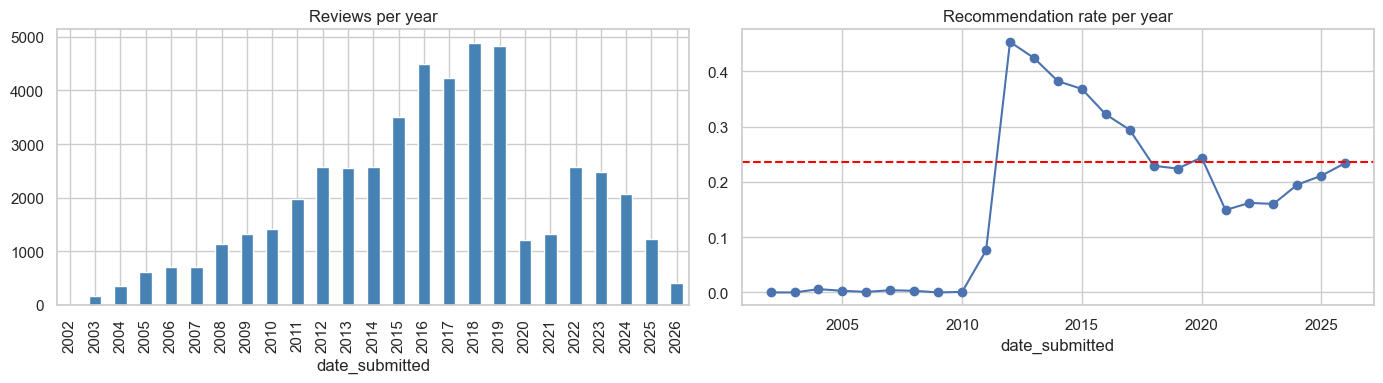

In [19]:
#time profile
by_year = df_clean.groupby(df_clean["date_submitted"].dt.year).agg(
    n_reviews = ("review_id", "size"),
    recommend_rate = ("recommended", "mean")
).round(3)
display(by_year)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_year["n_reviews"].plot(kind="bar", ax=axes[0], color="steelblue", title="Reviews per year")
by_year["recommend_rate"].plot(ax=axes[1], marker="o", title="Recommendation rate per year")
axes[1].axhline(df_clean["recommended"].mean(), color="red", linestyle="--")
plt.tight_layout()
plt.show()

In [20]:
#Experiece at airport and type of traveller
for col in ["experience_at_airport", "type_of_traveller"]:
    display(
        df_clean.groupby(col)["recommended"].agg(
            n="size", recommend_rate="mean"
        ).round(3).sort_values("n", ascending=False)
    )

df_clean["nationality_grouped"].value_counts().head(10)

,n,recommend_rate
experience_at_airport,,
Departure Only,12336,0.198
Arrival and Departure,11832,0.322
Transit,4091,0.219
Arrival Only,3992,0.201


,n,recommend_rate
type_of_traveller,,
Couple Leisure,9636,0.205
Solo Leisure,9369,0.319
Family Leisure,7170,0.236
Business,6054,0.211


nationality_grouped
United Kingdom    15782
United States      8855
Other              5114
Australia          3034
Canada             1943
Germany            1106
Netherlands         857
Ireland             852
India               781
France              688
Name: count, dtype: int64

,1.0,2.0,3.0,4.0,5.0
queuing_times,0.46,0.11,0.15,0.13,0.15
terminal_cleanliness,0.20,0.16,0.25,0.20,0.20
terminal_seating,0.39,0.19,0.18,0.14,0.10
terminal_signs,0.29,0.18,0.20,0.17,0.16
food_beverages,0.37,0.21,0.20,0.14,0.09
airport_shopping,0.31,0.18,0.24,0.15,0.12
airport_staff,0.51,0.14,0.13,0.11,0.11
wifi_connectivity,0.37,0.15,0.18,0.15,0.14


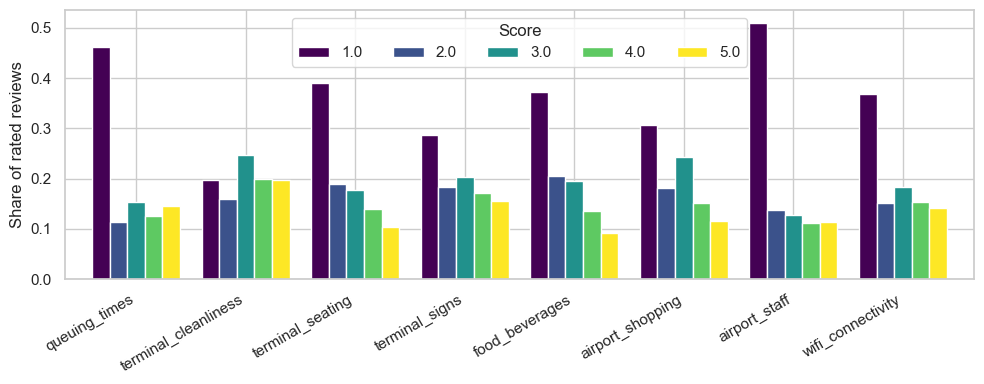

In [21]:
#Rating distribution
dist = df_clean[rating_cols].apply(pd.Series.value_counts, normalize=True).T
display(dist.round(2))

ax = dist.plot(kind="bar", figsize=(10, 4), width=0.8, colormap="viridis")
ax.set_ylabel("Share of rated reviews")
ax.set_xlabel("")
ax.legend(title="Score", ncol=5)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

#### Section 3 notes

- **23.6%** of reviews recommend the airport, which is the baseline for later comparisons.
- The recommendation rate is close to 0 until 2010, then **45.3%** in 2012, and falls to **14.9%** in 2021. Years before 2004 have too few reviews.
- The verified label only exists from 2017, so any verified vs non-verified comparison has to stay within 2017 onwards.
- Arrival and Departure (**32.2%**) and Solo Leisure (**31.9%**) recommend the most.
- Score 1 is the most common score in 7 of 8 rating columns, mostly for `airport_staff` (**51%**).


### 4. Airport comparison


In [22]:
#Import airport
airports = pd.read_csv("../../Data/raw/airports.csv", encoding="utf-8-sig")
airports.head()

,airport_id,airport_name
0,1,ANR Robinson International
1,2,Aalborg
2,3,Aarhus
3,4,Abbotsford Intl
4,5,Aberdeen


In [23]:
#Reviews per airport
per_airport = (
    df_clean.groupby("airport_id")
    .agg(n_reviews=("review_id", "size"), recommend_rate=("recommended", "mean"))
    .reset_index()
    .merge(airports, on="airport_id", how="left")
)

per_airport["n_reviews"].describe().round(1)

count    1004.0
mean       49.2
std       118.2
min         1.0
25%         2.0
50%         7.0
75%        36.0
max      1397.0
Name: n_reviews, dtype: float64

In [24]:
#Sample size threshold
rows = []
for t in (30, 50, 100, 200):
    sub = per_airport[per_airport["n_reviews"] >= t]
    rows.append({
        "min_reviews": t,
        "airports": len(sub),
        "share_of_reviews": round(sub["n_reviews"].sum() / len(df_clean), 3),
    })

pd.DataFrame(rows)


,min_reviews,airports,share_of_reviews
0,30,283,0.909
1,50,209,0.851
2,100,134,0.740
3,200,66,0.546


In [25]:
#Recommendation per airport
MIN_REIVEWS = 50
ranked = per_airport[per_airport["n_reviews"] >= MIN_REIVEWS].copy()
ranked["recommend_rate"] = ranked["recommend_rate"].round(3)

ranked["recommend_rate"].describe()

count    209.000000
mean       0.234914
std        0.124240
min        0.013000
25%        0.142000
50%        0.210000
75%        0.319000
max        0.736000
Name: recommend_rate, dtype: float64

In [29]:
#Top and bottom 10 airport by recommend_rate
cols = ["airport_name", "n_reviews", "recommend_rate"]

display (ranked.sort_values("recommend_rate", ascending=False).head(10)[cols])
display (ranked.sort_values("recommend_rate").head(10)[cols])

,airport_name,n_reviews,recommend_rate
910,Tokyo Haneda,91,0.736
838,Singapore Changi,471,0.639
388,Hong Kong,339,0.584
369,Hanoi,124,0.581
361,Hamad Doha,288,0.566
379,Helsinki Vantaa,214,0.547
848,Southend,70,0.514
403,Incheon,175,0.491
883,Taipei,145,0.490
887,Tampa,74,0.473


,airport_name,n_reviews,recommend_rate
346,Grenoble,77,0.013
314,Frankfurt Hahn,52,0.019
100,Berlin Brandenburg,210,0.033
101,Berlin Schonefeld,183,0.044
131,Bordeaux,194,0.052
787,Salt Lake City,260,0.054
43,Antalya,95,0.063
380,Heraklion,168,0.065
600,Montego Bay,60,0.067
818,Seattle,261,0.080


### 8. Save processed data


In [27]:
#Save processed data
#Main table: no review text, no raw nationality or date_visit
main_cols = [
    "review_id", "airport_id", "customer_name", "date_submitted", "verify", "recommended",
    "experience_at_airport", "type_of_traveller", "nationality_grouped",
] + rating_cols

main = df_clean[main_cols]
text = df_clean[["review_id", "review"]]

assert main["review_id"].is_unique
assert len(main) == len(text) == 49408
assert set(main["review_id"]) == set(text["review_id"])

main.to_csv("../../Data/processed/airport_reviews_clean.csv", index=False, encoding="utf-8-sig")
text.to_csv("../../Data/processed/airport_review_text.csv", index=False, encoding="utf-8-sig")

print("Main table:", main.shape, "| Text table:", text.shape)

Main table: (49408, 17) | Text table: (49408, 2)
